## Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

### Définir le chemin des données

In [2]:
DATA_DIR = Path("../jeu_donnees_referentiel_produit")

fichiers = {
    "PIM": DATA_DIR / "01_PIM_catalogue_produits.csv",
    "ERP": DATA_DIR / "02_ERP_articles.csv",
    "Marketplace": DATA_DIR / "03_Marketplace_offres_vendeurs.csv"
}

### Charger les trois sources

In [3]:
pim = pd.read_csv(fichiers["PIM"])
erp = pd.read_csv(fichiers["ERP"])
marketplace = pd.read_csv(fichiers["Marketplace"])

### Vérifier le chargement

In [4]:
for nom, df in {
    "PIM": pim,
    "ERP": erp,
    "Marketplace": marketplace
}.items():
    print(f"\n===== {nom} =====")
    print("Dimensions :", df.shape)
    display(df.head())


===== PIM =====
Dimensions : (102, 11)


,product_id,product_name,brand,category,gtin,model,specification,color,status,created_at,updated_at
0,P0001,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,128 Go,Noir,ACTIVE,2025-02-02,2026-02-02
1,P0002,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,128 Go,Noir,ACTIVE,2025-03-03,2026-03-03
2,P0003,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,256 Go,Titane,ACTIVE,2025-04-04,2026-04-04
3,P0004,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,256 Go,Noir,ACTIVE,2025-05-05,2026-05-05
4,P0005,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,128 Go,Noir,ACTIVE,2025-06-06,2026-06-06



===== ERP =====
Dimensions : (101, 11)


,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
0,ART-1001,SAMSUNG - Galaxy S24 128 Go,SAMSUNG,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,2982.11,ACTIF,2025-02-02
1,ART-1002,APPLE - iPhone 15 128 Go,APPLE,Smartphone,3.700000e+12,iPhone 15,128 Go,Noir,7409.34,ACTIF,2025-03-03
2,ART-1003,APPLE - iPhone 15 Pro 256 Go,APPLE,Smartphone,3.700000e+12,iPhone 15 Pro,256 Go,Titane,433.71,ACTIF,2025-04-04
3,ART-1004,XIAOMI - Redmi Note 13 256 Go,XIAOMI,Smartphone,3.700000e+12,Redmi Note 13,256 Go,Noir,626.08,ACTIF,2025-05-05
4,ART-1005,GOOGLE - Pixel 8 128 Go,GOOGLE,Smartphone,3.700000e+12,Pixel 8,128 Go,Noir,5236.22,ACTIF,2025-06-06



===== Marketplace =====
Dimensions : (110, 13)


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
0,OFF-5001,SKU-0001,SELLER-02,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,128 Go,Noir,1937.56,0.0,ACTIVE,2026-02-02
1,OFF-5002,SKU-0002,SELLER-03,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,128 Go,Noir,1265.44,0.0,ACTIVE,2026-03-03
2,OFF-5003,SKU-0003,SELLER-04,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,256 Go,Titane,5288.70,1.0,ACTIVE,2026-04-04
3,OFF-7003,ALT-003,SELLER-09,Apple iPhone 15 Pro 256 Go - livraison rapide,Apple,Smartphone,3700000000003,256 Go,Titane,1224.95,30.0,ACTIVE,2026-10-15
4,OFF-5004,SKU-0004,SELLER-05,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,256 Go,Noir,6850.63,10.0,ACTIVE,2026-05-05


In [5]:
sources = {
    "PIM": pim,
    "ERP": erp,
    "Marketplace": marketplace
}

### Examiner la structure de chaque source

In [6]:
for nom, df in sources.items():
    print(f"\n{'='*50}")
    print(f"SOURCE : {nom}")
    print(f"{'='*50}")

    df.info()


SOURCE : PIM
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     102 non-null    object
 1   product_name   97 non-null     object
 2   brand          101 non-null    object
 3   category       102 non-null    object
 4   gtin           95 non-null     object
 5   model          101 non-null    object
 6   specification  69 non-null     object
 7   color          101 non-null    object
 8   status         102 non-null    object
 9   created_at     102 non-null    object
 10  updated_at     100 non-null    object
dtypes: object(11)
memory usage: 8.9+ KB

SOURCE : ERP
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   article_id       101 non-null    object 
 1   libelle_article  10

### Mesurer la complétude

In [7]:
for nom, df in sources.items():

    print(f"\n===== COMPLETUDE : {nom} =====")

    rapport = pd.DataFrame({
        "Valeurs_manquantes": df.isnull().sum(),
        "Taux_manquant_%": (
            df.isnull().mean() * 100
        ).round(2)
    })

    display(rapport.sort_values(
        by="Taux_manquant_%",
        ascending=False
    ))


===== COMPLETUDE : PIM =====


,Valeurs_manquantes,Taux_manquant_%
specification,33,32.35
gtin,7,6.86
product_name,5,4.90
updated_at,2,1.96
brand,1,0.98
color,1,0.98
model,1,0.98
product_id,0,0.00
category,0,0.00
status,0,0.00



===== COMPLETUDE : ERP =====


,Valeurs_manquantes,Taux_manquant_%
caracteristique,32,31.68
code_barres,6,5.94
article_id,0,0.00
marque,0,0.00
libelle_article,0,0.00
famille_article,0,0.00
modele,0,0.00
couleur,0,0.00
prix_achat,0,0.00
statut,0,0.00



===== COMPLETUDE : Marketplace =====


,Valeurs_manquantes,Taux_manquant_%
variant,35,31.82
stock_quantity,11,10.00
brand_name,9,8.18
barcode,5,4.55
color_name,1,0.91
titre_annonce,0,0.00
seller_id,0,0.00
seller_sku,0,0.00
offer_id,0,0.00
category_name,0,0.00


### Vérifier les doublons

In [8]:
for nom, df in sources.items():

    print(f"\n===== DOUBLONS : {nom} =====")

    print("Doublons de lignes :", df.duplicated().sum())

    identifiant = df.columns[0]

    print(
        f"Doublons sur {identifiant} :",
        df[identifiant].duplicated().sum()
    )


===== DOUBLONS : PIM =====
Doublons de lignes : 0
Doublons sur product_id : 0

===== DOUBLONS : ERP =====
Doublons de lignes : 0
Doublons sur article_id : 0

===== DOUBLONS : Marketplace =====
Doublons de lignes : 0
Doublons sur offer_id : 0


### Détecter les anomalies numériques

In [9]:
# ERP : prix d'achat négatifs
print("Prix d'achat négatifs dans ERP :")
display(erp[erp["prix_achat"] < 0])

# Marketplace : prix de vente négatifs
print("Prix de vente négatifs dans Marketplace :")
display(marketplace[marketplace["price_mad"] < 0])

# Marketplace : stocks négatifs
print("Stocks négatifs dans Marketplace :")
display(marketplace[marketplace["stock_quantity"] < 0])

Prix d'achat négatifs dans ERP :


,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
100,ART-DUP-01,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,-50.0,ACTIF,2026-13-01


Prix de vente négatifs dans Marketplace :


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
109,OFF-ERR-01,SKU-ERR,SELLER-99,???,Marque inconnue,Divers,ABC123,NaN,NaN,-10.0,-5.0,UNKNOWN,2026-02-30


Stocks négatifs dans Marketplace :


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
6,OFF-5006,SKU-0006,SELLER-07,Sony WH-1000XM5,Sony,Casque audio,3700000000006,NaN,Noir,1728.12,-2.0,ACTIVE,2026-07-07
10,OFF-5009,SKU-0009,SELLER-10,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,16 Go RAM / 512 Go SSD,Argent,6032.51,-2.0,INACTIVE,2026-10-10
26,OFF-5023,SKU-0023,SELLER-12,Adidas Ultraboost Light 42,Adidas,Chaussures,3700000000023,42,Noir,8240.27,-2.0,ACTIVE,2026-04-24
31,OFF-5028,SKU-0028,SELLER-05,Xiaomi Redmi Note 13 édition 28 256 Go,Xiaomi,Divers,3700000000028,256 Go,Noir,9392.64,-2.0,PENDING,2026-09-02
32,OFF-5029,SKU-0029,SELLER-06,Google Pixel 8 édition 29 128 Go,Google,Smartphone,3700000000029,128 Go,Noir,1376.91,-2.0,ACTIVE,2026-10-03
36,OFF-5033,SKU-0033,SELLER-10,Dell XPS 13 édition 33 16 Go RAM / 512 Go SSD,NaN,Ordinateur portable,3700000000033,16 Go RAM / 512 Go SSD,Argent,2614.24,-2.0,ACTIVE,2026-04-07
57,OFF-5052,SKU-0052,SELLER-05,Xiaomi Redmi Note 13 édition 52 256 Go,Xiaomi,Smartphone,3700000000052,256 Go,Noir,11664.14,-2.0,PENDING,2026-03-26
67,OFF-5061,SKU-0061,SELLER-02,Logitech MX Master 3S édition 61,Logitech,Souris,3700000000061,NaN,Graphite,8000.33,-2.0,ACTIVE,2026-02-08
85,OFF-5078,SKU-0078,SELLER-07,Sony WH-1000XM5 édition 78,Sony,Casque audio,3700000000078,NaN,Noir,11929.76,-2.0,INACTIVE,2026-09-25
104,OFF-5096,SKU-0096,SELLER-01,"Samsonite Guardit 2.0 édition 96 15,6 pouces",Samsonite,Sac à dos,3700000000096,"15,6 pouces",Noir,5447.61,-2.0,PENDING,2026-07-16


In [10]:
for nom, df, colonne in [
    ("PIM", pim, "brand"),
    ("ERP", erp, "marque"),
    ("Marketplace", marketplace, "brand_name")
]:

    print(f"\n===== MARQUES : {nom} =====")

    display(
        df[colonne]
        .value_counts(dropna=False)
        .head(20)
    )


===== MARQUES : PIM =====


brand
Apple        18
Samsung      10
Logitech      8
Xiaomi        5
Google        4
Sony          4
Dell          4
JBL           4
HP            4
Lenovo        4
SanDisk       4
Canon         4
LG            4
Dyson         4
Philips       4
Nespresso     4
Nike          4
Adidas        4
Samsonite     4
NaN           1
Name: count, dtype: int64


===== MARQUES : ERP =====


marque
APPLE        15
SAMSUNG       7
LOGITECH      7
SONY          4
DELL          4
HP            4
XIAOMI        4
CANON         4
SANDISK       4
ADIDAS        4
PHILIPS       4
SAMSONITE     4
DYSON         3
LG            3
GOOGLE        3
JBL           3
NESPRESSO     3
LENOVO        3
NIKE          3
Apple         3
Name: count, dtype: int64


===== MARQUES : Marketplace =====


brand_name
Apple        21
Samsung       9
NaN           9
Logitech      8
Xiaomi        5
Nespresso     5
Sony          4
Samsonite     4
Dell          4
HP            4
Canon         4
LG            4
JBL           4
Philips       4
Dyson         4
Adidas        4
Google        3
SanDisk       3
Lenovo        3
Nike          3
Name: count, dtype: int64

## Étape 4 — Construire le diagnostic qualité

In [11]:
def diagnostic_general(df, nom_source):

    total_cellules = df.shape[0] * df.shape[1]
    cellules_manquantes = df.isna().sum().sum()

    resultat = {
        "Source": nom_source,
        "Nombre de lignes": df.shape[0],
        "Nombre de colonnes": df.shape[1],
        "Doublons exacts": df.duplicated().sum(),
        "Cellules manquantes": cellules_manquantes,
        "Taux de complétude (%)": round(
            (1 - cellules_manquantes / total_cellules) * 100, 2
        ) if total_cellules else 0
    }

    return resultat


resultats = []

for nom, df in sources.items():
    resultats.append(diagnostic_general(df, nom))

rapport_general = pd.DataFrame(resultats)

display(rapport_general)

,Source,Nombre de lignes,Nombre de colonnes,Doublons exacts,Cellules manquantes,Taux de complétude (%)
0,PIM,102,11,0,50,95.54
1,ERP,101,11,0,38,96.58
2,Marketplace,110,13,0,61,95.73


In [12]:
# Calculer le taux de complétude par colonne
def analyser_completude(df, nom_source):

    resultat = pd.DataFrame({
        "Valeurs renseignées": df.notna().sum(),
        "Valeurs manquantes": df.isna().sum(),
        "Taux de complétude (%)": (
            df.notna().mean() * 100
        ).round(2)
    })

    resultat.index.name = "Attribut"

    print(f"\n===== COMPLÉTUDE : {nom_source} =====")

    return resultat.sort_values(
        "Taux de complétude (%)",
        ascending=True
    )

In [13]:
for nom, df in sources.items():

    display(analyser_completude(df, nom))


===== COMPLÉTUDE : PIM =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
specification,69,33,67.65
gtin,95,7,93.14
product_name,97,5,95.10
updated_at,100,2,98.04
model,101,1,99.02
color,101,1,99.02
brand,101,1,99.02
category,102,0,100.00
product_id,102,0,100.00



===== COMPLÉTUDE : ERP =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
caracteristique,69,32,68.32
code_barres,95,6,94.06
article_id,101,0,100.00
libelle_article,101,0,100.00
famille_article,101,0,100.00
marque,101,0,100.00
modele,101,0,100.00
couleur,101,0,100.00
prix_achat,101,0,100.00



===== COMPLÉTUDE : Marketplace =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
variant,75,35,68.18
stock_quantity,99,11,90.00
brand_name,101,9,91.82
barcode,105,5,95.45
color_name,109,1,99.09
seller_id,110,0,100.00
titre_annonce,110,0,100.00
offer_id,110,0,100.00
category_name,110,0,100.00


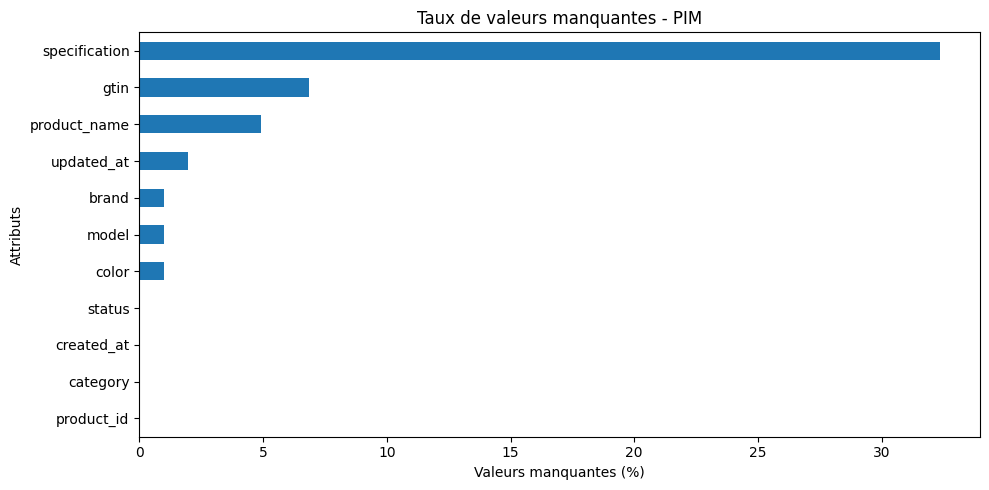

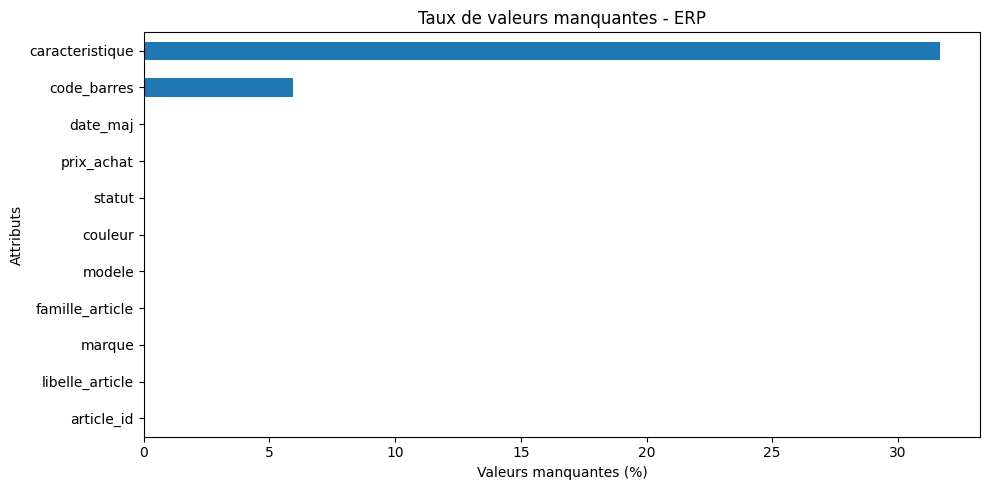

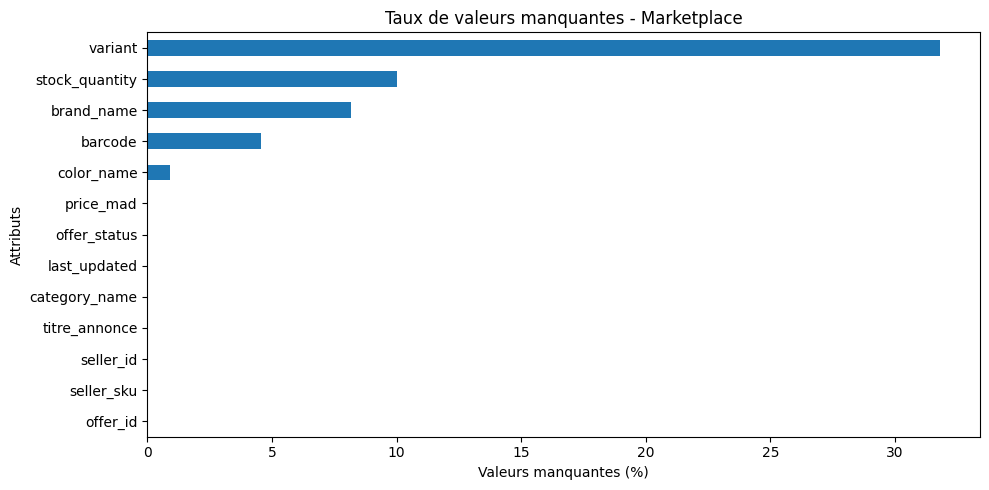

In [14]:
for nom, df in sources.items():

    taux_manquant = (df.isna().mean() * 100).sort_values()

    plt.figure(figsize=(10, 5))

    taux_manquant.plot(kind="barh")

    plt.title(f"Taux de valeurs manquantes - {nom}")
    plt.xlabel("Valeurs manquantes (%)")
    plt.ylabel("Attributs")

    plt.tight_layout()
    plt.show()

In [15]:
# Contrôler les valeurs métier incorrectes
controles = {
    "ERP - Prix d'achat négatif": (
        erp, "prix_achat", lambda x: x < 0
    ),
    "Marketplace - Prix négatif": (
        marketplace, "price_mad", lambda x: x < 0
    ),
    "Marketplace - Stock négatif": (
        marketplace, "stock_quantity", lambda x: x < 0
    )
}

for nom_controle, (df, colonne, condition) in controles.items():

    valeurs = pd.to_numeric(df[colonne], errors="coerce")
    anomalies = df[condition(valeurs)]

    print(f"\n{nom_controle}")
    print("Nombre d'anomalies :", len(anomalies))

    display(anomalies)


ERP - Prix d'achat négatif
Nombre d'anomalies : 1


Attribut,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
100,ART-DUP-01,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,-50.0,ACTIF,2026-13-01



Marketplace - Prix négatif
Nombre d'anomalies : 1


Attribut,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
109,OFF-ERR-01,SKU-ERR,SELLER-99,???,Marque inconnue,Divers,ABC123,NaN,NaN,-10.0,-5.0,UNKNOWN,2026-02-30



Marketplace - Stock négatif
Nombre d'anomalies : 11


Attribut,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
6,OFF-5006,SKU-0006,SELLER-07,Sony WH-1000XM5,Sony,Casque audio,3700000000006,NaN,Noir,1728.12,-2.0,ACTIVE,2026-07-07
10,OFF-5009,SKU-0009,SELLER-10,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,16 Go RAM / 512 Go SSD,Argent,6032.51,-2.0,INACTIVE,2026-10-10
26,OFF-5023,SKU-0023,SELLER-12,Adidas Ultraboost Light 42,Adidas,Chaussures,3700000000023,42,Noir,8240.27,-2.0,ACTIVE,2026-04-24
31,OFF-5028,SKU-0028,SELLER-05,Xiaomi Redmi Note 13 édition 28 256 Go,Xiaomi,Divers,3700000000028,256 Go,Noir,9392.64,-2.0,PENDING,2026-09-02
32,OFF-5029,SKU-0029,SELLER-06,Google Pixel 8 édition 29 128 Go,Google,Smartphone,3700000000029,128 Go,Noir,1376.91,-2.0,ACTIVE,2026-10-03
36,OFF-5033,SKU-0033,SELLER-10,Dell XPS 13 édition 33 16 Go RAM / 512 Go SSD,NaN,Ordinateur portable,3700000000033,16 Go RAM / 512 Go SSD,Argent,2614.24,-2.0,ACTIVE,2026-04-07
57,OFF-5052,SKU-0052,SELLER-05,Xiaomi Redmi Note 13 édition 52 256 Go,Xiaomi,Smartphone,3700000000052,256 Go,Noir,11664.14,-2.0,PENDING,2026-03-26
67,OFF-5061,SKU-0061,SELLER-02,Logitech MX Master 3S édition 61,Logitech,Souris,3700000000061,NaN,Graphite,8000.33,-2.0,ACTIVE,2026-02-08
85,OFF-5078,SKU-0078,SELLER-07,Sony WH-1000XM5 édition 78,Sony,Casque audio,3700000000078,NaN,Noir,11929.76,-2.0,INACTIVE,2026-09-25
104,OFF-5096,SKU-0096,SELLER-01,"Samsonite Guardit 2.0 édition 96 15,6 pouces",Samsonite,Sac à dos,3700000000096,"15,6 pouces",Noir,5447.61,-2.0,PENDING,2026-07-16


In [16]:
mapping = {
    "PIM": {
        "product_name": "product_name",
        "brand": "brand",
        "category": "category",
        "gtin": "gtin",
        "model": "model",
        "color": "color",
        "specification": "specification"
    },

    "ERP": {
        "product_name": "libelle_article",
        "brand": "marque",
        "category": "famille_article",
        "gtin": "code_barres",
        "model": "modele",
        "color": "couleur",
        "specification": "caracteristique"
    },

    "Marketplace": {
        "product_name": "titre_annonce",
        "brand": "brand_name",
        "category": "category_name",
        "gtin": "barcode",
        "model": None,
        "color": "color_name",
        "specification": "variant"
    }
}

In [17]:
for source, correspondances in mapping.items():
    print(f"\n--- {source} ---")

    for cible, colonne in correspondances.items():
        if colonne is None:
            print(f"{cible}: non disponible dans le mapping initial")
        elif colonne in sources[source].columns:
            print(f"{cible}: OK ({colonne})")
        else:
            print(f"{cible}: COLONNE INTROUVABLE ({colonne})")


--- PIM ---
product_name: OK (product_name)
brand: OK (brand)
category: OK (category)
gtin: OK (gtin)
model: OK (model)
color: OK (color)
specification: OK (specification)

--- ERP ---
product_name: OK (libelle_article)
brand: OK (marque)
category: OK (famille_article)
gtin: OK (code_barres)
model: OK (modele)
color: OK (couleur)
specification: OK (caracteristique)

--- Marketplace ---
product_name: OK (titre_annonce)
brand: OK (brand_name)
category: OK (category_name)
gtin: OK (barcode)
model: non disponible dans le mapping initial
color: OK (color_name)
specification: OK (variant)


In [18]:
def harmoniser_source(df, nom_source, correspondances):

    donnees = pd.DataFrame(index=df.index)

    for attribut_cible, colonne_source in correspondances.items():

        if colonne_source is not None and colonne_source in df.columns:
            donnees[attribut_cible] = df[colonne_source]
        else:
            donnees[attribut_cible] = pd.NA

    donnees["source_system"] = nom_source

    return donnees

In [19]:
pim_harmonise = harmoniser_source(pim, "PIM", mapping["PIM"])
erp_harmonise = harmoniser_source(erp, "ERP", mapping["ERP"])
marketplace_harmonise = harmoniser_source(
    marketplace, "Marketplace", mapping["Marketplace"]
)

In [22]:
donnees_consolidees = pd.concat(
    [
        pim_harmonise,
        erp_harmonise,
        marketplace_harmonise
    ],
    ignore_index=True
)

print("Dimensions :", donnees_consolidees.shape)

display(donnees_consolidees.head(10))

Dimensions : (313, 8)


,product_name,brand,category,gtin,model,color,specification,source_system
0,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,Noir,128 Go,PIM
1,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,Noir,128 Go,PIM
2,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,Titane,256 Go,PIM
3,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,Noir,256 Go,PIM
4,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,Noir,128 Go,PIM
5,Sony WH-1000XM5,Sony,Casque audio,3700000000006,WH-1000XM5,Noir,NaN,PIM
6,JBL Tune 760NC,JBL,Casque audio,3700000000007,Tune 760NC,Noir,NaN,PIM
7,Apple AirPods Pro 2,Apple,Écouteurs,3700000000008,AirPods Pro 2,Blanc,NaN,PIM
8,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,XPS 13,Argent,16 Go RAM / 512 Go SSD,PIM
9,HP Pavilion 15 8 Go RAM / 512 Go SSD,HP,Ordinateur portable,3700000000010,Pavilion 15,Argent,8 Go RAM / 512 Go SSD,PIM


## Normalisation des données

In [23]:
colonnes_textuelles = [
    "product_name",
    "brand",
    "category",
    "model",
    "color",
    "specification"
]

def normaliser_texte(valeur):

    if pd.isna(valeur):
        return pd.NA

    return " ".join(str(valeur).strip().split()).casefold()


donnees_normalisees = donnees_consolidees.copy()

for colonne in colonnes_textuelles:
    donnees_normalisees[colonne] = (
        donnees_normalisees[colonne].apply(normaliser_texte)
    )

display(donnees_normalisees.head(10))

,product_name,brand,category,gtin,model,color,specification,source_system
0,samsung galaxy s24 128 go,samsung,smartphone,3700000000001,galaxy s24,noir,128 go,PIM
1,apple iphone 15 128 go,apple,smartphone,3700000000002,iphone 15,noir,128 go,PIM
2,apple iphone 15 pro 256 go,apple,smartphone,3700000000003,iphone 15 pro,titane,256 go,PIM
3,xiaomi redmi note 13 256 go,xiaomi,smartphone,3700000000004,redmi note 13,noir,256 go,PIM
4,google pixel 8 128 go,google,smartphone,3700000000005,pixel 8,noir,128 go,PIM
5,sony wh-1000xm5,sony,casque audio,3700000000006,wh-1000xm5,noir,<NA>,PIM
6,jbl tune 760nc,jbl,casque audio,3700000000007,tune 760nc,noir,<NA>,PIM
7,apple airpods pro 2,apple,écouteurs,3700000000008,airpods pro 2,blanc,<NA>,PIM
8,dell xps 13 16 go ram / 512 go ssd,dell,ordinateur portable,3700000000009,xps 13,argent,16 go ram / 512 go ssd,PIM
9,hp pavilion 15 8 go ram / 512 go ssd,hp,ordinateur portable,3700000000010,pavilion 15,argent,8 go ram / 512 go ssd,PIM


In [24]:
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

donnees_consolidees.to_csv(
    OUTPUT_DIR / "donnees_consolidees.csv",
    index=False
)

donnees_normalisees.to_csv(
    OUTPUT_DIR / "donnees_normalisees.csv",
    index=False
)

print("Fichiers sauvegardés avec succès.")

Fichiers sauvegardés avec succès.


### 4.2 - Catalogue des règles de qualité

In [25]:
# Formaliser le catalogue des règles
regles_qualite = pd.DataFrame([
    ["DQ01", "Complétude", "Nom produit obligatoire", "product_name"],
    ["DQ02", "Complétude", "Marque obligatoire", "brand"],
    ["DQ03", "Complétude", "Catégorie obligatoire", "category"],
    ["DQ04", "Validité", "GTIN au format numérique et longueur autorisée", "gtin"],
    ["DQ05", "Validité", "Prix d'achat positif ou nul", "prix_achat"],
    ["DQ06", "Validité", "Prix de vente positif ou nul", "price_mad"],
    ["DQ07", "Validité", "Stock positif ou nul", "stock_quantity"],
    ["DQ08", "Unicité", "Absence de doublons exacts", "toutes les colonnes"],
    ["DQ09", "Cohérence", "Homogénéité des marques", "brand"],
    ["DQ10", "Cohérence", "Cohérence des GTIN entre sources", "gtin"],
], columns=[
    "ID règle", "Dimension", "Description", "Attribut concerné"
])

display(regles_qualite)

,ID règle,Dimension,Description,Attribut concerné
0,DQ01,Complétude,Nom produit obligatoire,product_name
1,DQ02,Complétude,Marque obligatoire,brand
2,DQ03,Complétude,Catégorie obligatoire,category
3,DQ04,Validité,GTIN au format numérique et longueur autorisée,gtin
4,DQ05,Validité,Prix d'achat positif ou nul,prix_achat
5,DQ06,Validité,Prix de vente positif ou nul,price_mad
6,DQ07,Validité,Stock positif ou nul,stock_quantity
7,DQ08,Unicité,Absence de doublons exacts,toutes les colonnes
8,DQ09,Cohérence,Homogénéité des marques,brand
9,DQ10,Cohérence,Cohérence des GTIN entre sources,gtin


In [26]:
def controle_completude(df, colonnes, nom_source):

    resultats = []

    for colonne in colonnes:

        if colonne not in df.columns:
            continue

        total = len(df)
        manquantes = df[colonne].isna().sum()

        taux = (
            (total - manquantes) / total * 100
            if total > 0 else 0
        )

        resultats.append({
            "Source": nom_source,
            "Attribut": colonne,
            "Valeurs manquantes": manquantes,
            "Taux de complétude (%)": round(taux, 2)
        })

    return pd.DataFrame(resultats)

In [27]:
colonnes_obligatoires = {
    "PIM": ["product_name", "brand", "category"],
    "ERP": ["libelle_article", "marque", "famille_article"],
    "Marketplace": ["titre_annonce", "brand_name", "category_name"]
}

rapport_completude = pd.concat(
    [
        controle_completude(
            sources[nom],
            colonnes,
            nom
        )
        for nom, colonnes in colonnes_obligatoires.items()
    ],
    ignore_index=True
)

display(rapport_completude)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%)
0,PIM,product_name,5,95.10
1,PIM,brand,1,99.02
2,PIM,category,0,100.00
3,ERP,libelle_article,0,100.00
4,ERP,marque,0,100.00
5,ERP,famille_article,0,100.00
6,Marketplace,titre_annonce,0,100.00
7,Marketplace,brand_name,9,91.82
8,Marketplace,category_name,0,100.00


In [27]:
identifiants = {
    "PIM": "product_id",
    "ERP": "article_code",
    "Marketplace": "offer_id"
}

In [28]:
for nom, df in sources.items():
    print(f"\n{nom}")
    print(df.columns.tolist())


PIM
['product_id', 'product_name', 'brand', 'category', 'gtin', 'model', 'specification', 'color', 'status', 'created_at', 'updated_at']

ERP
['article_id', 'libelle_article', 'marque', 'famille_article', 'code_barres', 'modele', 'caracteristique', 'couleur', 'prix_achat', 'statut', 'date_maj']

Marketplace
['offer_id', 'seller_sku', 'seller_id', 'titre_annonce', 'brand_name', 'category_name', 'barcode', 'variant', 'color_name', 'price_mad', 'stock_quantity', 'offer_status', 'last_updated']


In [29]:
rapport_unicite = pd.DataFrame([
    controle_unicite(
        sources[nom],
        nom,
        identifiant
    )
    for nom, identifiant in identifiants.items()
])

display(rapport_unicite)

NameError: name 'controle_unicite' is not defined

In [30]:
def controle_gtin(df, colonne, nom_source):

    gtin = df[colonne].astype("string").str.strip()

    renseigne = gtin.notna() & gtin.ne("")

    format_valide = (
        gtin.str.fullmatch(r"\d{8}|\d{12}|\d{13}|\d{14}")
        .fillna(False)
    )

    invalides = renseigne & ~format_valide

    return pd.DataFrame([{
        "Source": nom_source,
        "GTIN renseignés": int(renseigne.sum()),
        "GTIN invalides": int(invalides.sum()),
        "Taux de validité (%)": round(
            format_valide[renseigne].mean() * 100, 2
        ) if renseigne.sum() else 0
    }])

In [31]:
colonnes_gtin = {
    "PIM": "gtin",
    "ERP": "code_barres",
    "Marketplace": "barcode"
}

rapport_gtin = pd.concat([
    controle_gtin(sources[nom], colonne, nom)
    for nom, colonne in colonnes_gtin.items()
], ignore_index=True)

display(rapport_gtin)

,Source,GTIN renseignés,GTIN invalides,Taux de validité (%)
0,PIM,95,1,98.95
1,ERP,95,95,0.00
2,Marketplace,105,1,99.05


In [32]:
def controle_valeur_negative(df, colonne, nom_source):

    valeurs = pd.to_numeric(df[colonne], errors="coerce")

    invalides = valeurs < 0

    return {
        "Source": nom_source,
        "Attribut": colonne,
        "Valeurs négatives": int(invalides.sum())
    }

In [33]:
controles_numeriques = [
    (erp, "ERP", "prix_achat"),
    (marketplace, "Marketplace", "price_mad"),
    (marketplace, "Marketplace", "stock_quantity")
]

rapport_validite = pd.DataFrame([
    controle_valeur_negative(df, colonne, nom)
    for df, nom, colonne in controles_numeriques
])

display(rapport_validite)

,Source,Attribut,Valeurs négatives
0,ERP,prix_achat,1
1,Marketplace,price_mad,1
2,Marketplace,stock_quantity,11


In [36]:
colonnes_obligatoires = {
    "PIM": ["product_name", "brand", "category"],
    "ERP": ["libelle_article", "marque", "famille_article"],
    "Marketplace": ["titre_annonce", "brand_name", "category_name"]
}

rapport_completude = pd.concat([
    controle_completude(sources[nom], colonnes, nom)
    for nom, colonnes in colonnes_obligatoires.items()
], ignore_index=True)

display(rapport_completude)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%)
0,PIM,product_name,5,95.10
1,PIM,brand,1,99.02
2,PIM,category,0,100.00
3,ERP,libelle_article,0,100.00
4,ERP,marque,0,100.00
5,ERP,famille_article,0,100.00
6,Marketplace,titre_annonce,0,100.00
7,Marketplace,brand_name,9,91.82
8,Marketplace,category_name,0,100.00


In [37]:
rapport_global = pd.concat(
    [
        rapport_completude.assign(Dimension="Complétude"),
        rapport_gtin.assign(Dimension="Validité GTIN")
    ],
    ignore_index=True,
    sort=False
)

display(rapport_global)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%),Dimension,GTIN renseignés,GTIN invalides,Taux de validité (%)
0,PIM,product_name,5.0,95.10,Complétude,NaN,NaN,NaN
1,PIM,brand,1.0,99.02,Complétude,NaN,NaN,NaN
2,PIM,category,0.0,100.00,Complétude,NaN,NaN,NaN
3,ERP,libelle_article,0.0,100.00,Complétude,NaN,NaN,NaN
4,ERP,marque,0.0,100.00,Complétude,NaN,NaN,NaN
5,ERP,famille_article,0.0,100.00,Complétude,NaN,NaN,NaN
6,Marketplace,titre_annonce,0.0,100.00,Complétude,NaN,NaN,NaN
7,Marketplace,brand_name,9.0,91.82,Complétude,NaN,NaN,NaN
8,Marketplace,category_name,0.0,100.00,Complétude,NaN,NaN,NaN
9,PIM,NaN,NaN,NaN,Validité GTIN,95.0,1.0,98.95


In [35]:
for nom, df in sources.items():
    print(f"\n--- {nom} ---")
    print(df.columns.tolist())


--- PIM ---
['product_id', 'product_name', 'brand', 'category', 'gtin', 'model', 'specification', 'color', 'status', 'created_at', 'updated_at']

--- ERP ---
['article_id', 'libelle_article', 'marque', 'famille_article', 'code_barres', 'modele', 'caracteristique', 'couleur', 'prix_achat', 'statut', 'date_maj']

--- Marketplace ---
['offer_id', 'seller_sku', 'seller_id', 'titre_annonce', 'brand_name', 'category_name', 'barcode', 'variant', 'color_name', 'price_mad', 'stock_quantity', 'offer_status', 'last_updated']
